# 12 · Las emociones de Pitt: qué contienen las anotaciones y cuánto depende el resultado de cómo se agrupan

Pitt **no trae etiquetas de valencia**. Cada anuncio fue visto por 3–5 anotadores, que marcaron uno o más de **30 sentimientos** (`Sentiments.json`). En los notebooks 09–11 la valencia (positiva/negativa) se **construyó** con una asignación de sentimientos a valencias y una regla de mayoría. Este notebook revisa esa construcción.

**Parte 1 · Descripción de los 30 sentimientos**
1. Frecuencia: cuánto se usa cada sentimiento.
2. Acuerdo entre anotadores por sentimiento (κ de Fleiss).
3. Con qué otros sentimientos aparece cada uno: agrupación **desde los datos**, para contrastar con la asignación manual.
4. Sentimientos por tema del anuncio.

**Parte 2 · Sensibilidad de la valencia.** Se repite el experimento del notebook 10 (**CLIP congelado + sonda, solo la imagen**) con 4 asignaciones de sentimientos × 2 reglas de agregación. Si el rendimiento cambia poco, la conclusión no depende de la decisión de asignación.

**Parte 3 · ¿Qué sentimientos se reconocen desde la imagen?** Una sonda por sentimiento: ¿CLIP detecta *afraid*, *cheerful*, *eager*…? ¿Se relaciona con el acuerdo humano?

En ningún caso se usa texto, OCR ni otras anotaciones como entrada del modelo: **solo la imagen**. Las anotaciones solo definen la respuesta correcta.

## 0. Entorno, rutas y votos

In [1]:
import glob
import io
import json
import os
import random
import re
import time
import urllib.request
import zipfile
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision.transforms as T
from PIL import Image
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, cohen_kappa_score, f1_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    if not os.path.isdir('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    DRIVE_ROOT = '/content/drive/MyDrive/publicity_analysis'
    PITT_DIR = os.path.join(DRIVE_ROOT, 'pitt')
    IMG_DIR = '/content/work/pitt_256'
    PITT_CACHE_ZIP = os.path.join(PITT_DIR, 'etapa2_256.zip')
    OUT = os.path.join(DRIVE_ROOT, 'resultados', 'pitt_emociones')
else:
    PITT_DIR = 'pitt'
    IMG_DIR = os.path.expanduser('~/datasets/pitt_256')
    PITT_CACHE_ZIP = None
    OUT = os.path.join('resultados', 'pitt_emociones')
VOTOS_IMG = os.path.join(PITT_DIR, 'votos', 'image')
for d in (IMG_DIR, OUT):
    os.makedirs(d, exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
CLIP_NAME = 'openai/clip-vit-base-patch16'
URL_VOTOS = 'https://people.cs.pitt.edu/~kovashka/ads/annotations_images.zip'
URL_IMG = 'https://people.cs.pitt.edu/~mzhang/image_ads/'
UA = {'User-Agent': 'Mozilla/5.0 (research dataset downloader)'}
SEED = 0
N_POS = 2000           # positivos por variante (los negativos se usan todos), como en el notebook 10
N_RANDOM = 3000        # muestra aleatoria de anuncios para la parte 3
pd.set_option('display.float_format', '{:.3f}'.format)


def fetch(url, timeout=60, retries=3):
    for k in range(retries):
        try:
            with urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=timeout) as r:
                return r.read()
        except Exception:
            if k == retries - 1:
                raise
            time.sleep(1.5 * (k + 1))


if not os.path.exists(os.path.join(VOTOS_IMG, 'Sentiments.json')):
    with zipfile.ZipFile(io.BytesIO(fetch(URL_VOTOS))) as z:
        z.extractall(os.path.join(PITT_DIR, 'votos'))


def parse_list(path, enc):
    names, desc = {}, {}
    for line in open(path, encoding=enc):
        m = re.match(r'\s*(\d+)[.,]?\s+"([^"]+)"(?:.*ABBREVIATION:\s*"([^"]+)")?', line)
        if m:
            names[m.group(1)] = m.group(3) or m.group(2).lower()
            desc[names[m.group(1)]] = m.group(2)
    return names, desc


SENT_NAMES, SENT_DESC = parse_list(os.path.join(VOTOS_IMG, 'Sentiments_List.txt'), 'latin-1')
TOPIC_NAMES, _ = parse_list(os.path.join(VOTOS_IMG, 'Topics_List.txt'), 'utf-16')
SENTS = sorted(SENT_DESC)

# VOTOS[key] = lista (un elemento por anotador) de conjuntos de sentimientos
raw = json.load(open(os.path.join(VOTOS_IMG, 'Sentiments.json')))
VOTOS = {k: [frozenset(SENT_NAMES[str(i)] for i in v if str(i) in SENT_NAMES) for v in vs]
         for k, vs in raw.items() if len(vs) >= 2}
TOPICS = json.load(open(os.path.join(VOTOS_IMG, 'Topics.json')))
KEYS = sorted(VOTOS)
n_votos = sum(len(v) for v in VOTOS.values())
print(f'{len(KEYS)} anuncios · {n_votos} votos de anotadores · {len(SENTS)} sentimientos · dispositivo {DEVICE}')

30340 anuncios · 102340 votos de anotadores · 30 sentimientos · dispositivo mps


## Parte 1 · Los 30 sentimientos

### 1.1 Frecuencia y acuerdo

- **% de votos:** proporción de anotadores que marcaron el sentimiento.
- **% de anuncios con mayoría:** proporción de anuncios en que **más de la mitad** de sus anotadores lo marcaron.
- **κ de Fleiss** (binario: marcado / no marcado): acuerdo más allá del azar. < 0 pobre · 0–0,2 leve · 0,2–0,4 aceptable · 0,4–0,6 moderado.

El color indica la valencia que le asigna la variante **base** (la de los notebooks 09–11).

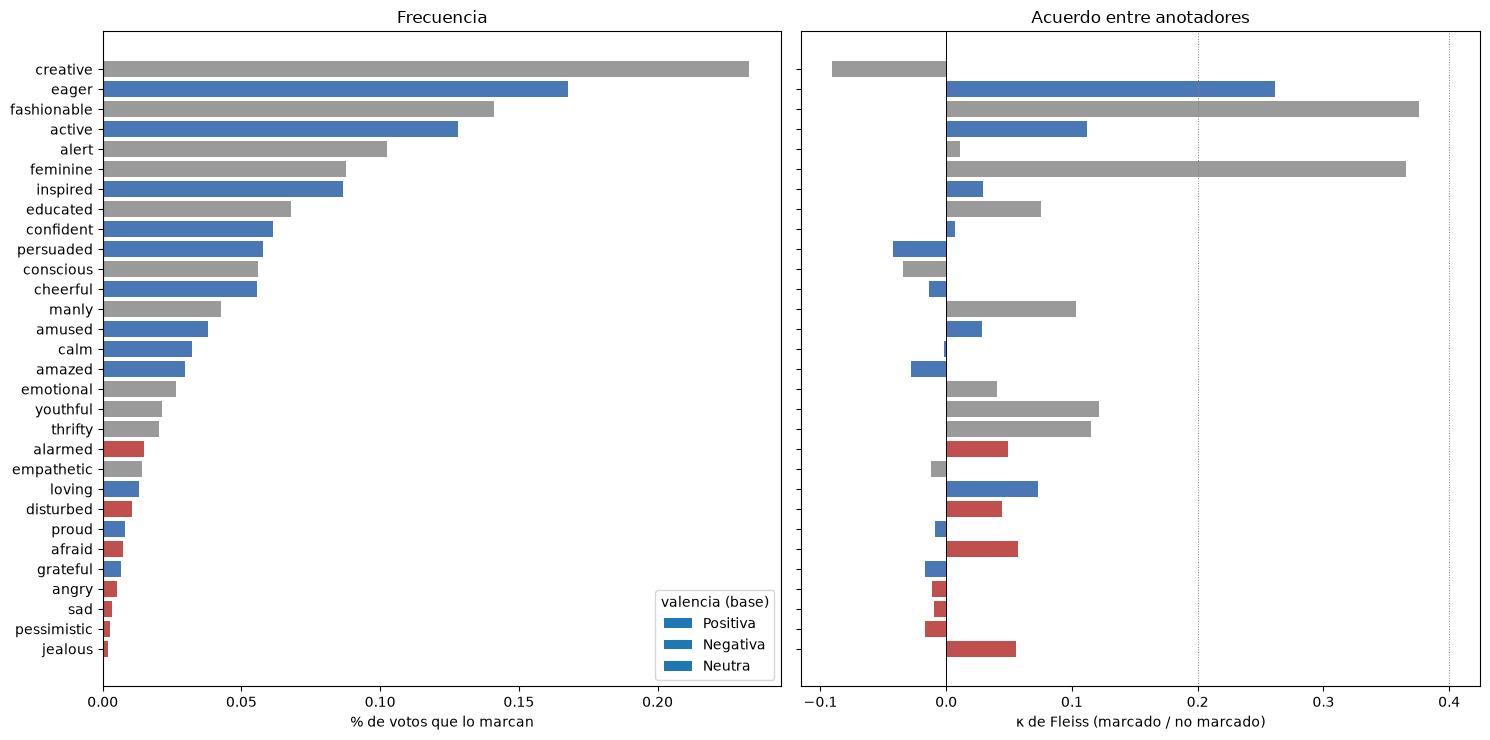

Sentimientos marcados por anotador: {1: 0.693, 2: 0.185, 3: 0.073, 4: 0.028, 5: 0.01, 6: 0.004} · media 1.54


,sentimiento,descripción,valencia_base,pct_votos,pct_anuncios_mayoria,kappa
0,creative,"Creative (inventive, productive)",Neutra,0.233,0.099,-0.091
1,eager,"Eager (hungry, thirsty, passionate)",Positiva,0.168,0.142,0.261
2,fashionable,"Fashionable (trendy, elegant, beautiful, attra...",Neutra,0.141,0.121,0.376
3,active,"Active (energetic, adventurous, vibrant, enthu...",Positiva,0.128,0.067,0.112
4,alert,"Alert (attentive, curious)",Neutra,0.103,0.025,0.011
5,feminine,"Feminine (womanly, girlish)",Neutra,0.088,0.072,0.366
6,inspired,"Inspired (motivated, ambitious, empowered, hop...",Positiva,0.087,0.022,0.030
7,educated,"Educated (informed, enlightened, smart, savvy,...",Neutra,0.068,0.018,0.075
8,confident,"Confident (assured, strong, healthy)",Positiva,0.061,0.015,0.007
9,persuaded,"Persuaded (impressed, enchanted, immersed)",Positiva,0.058,0.010,-0.042


In [2]:
POS_BASE = {'active', 'amazed', 'amused', 'calm', 'cheerful', 'confident', 'eager', 'grateful',
            'inspired', 'loving', 'persuaded', 'proud'}
NEG_BASE = {'afraid', 'alarmed', 'angry', 'disturbed', 'jealous', 'pessimistic', 'sad'}
val_base = lambda s: 'Positiva' if s in POS_BASE else 'Negativa' if s in NEG_BASE else 'Neutra'
COL = {'Positiva': '#4a78b5', 'Negativa': '#c0504d', 'Neutra': '#9a9a9a'}

# Matriz anuncio × sentimiento: cuántos anotadores lo marcaron (c) y cuántos anotadores tiene el anuncio (n)
si = {s: j for j, s in enumerate(SENTS)}
C = np.zeros((len(KEYS), len(SENTS)))
n_anot = np.array([len(VOTOS[k]) for k in KEYS], float)
for i, k in enumerate(KEYS):
    for v in VOTOS[k]:
        for s in v:
            C[i, si[s]] += 1


def fleiss_binario(c, n):
    # κ de Fleiss con 2 categorías (marcado / no marcado) y número variable de anotadores
    P_i = (c * (c - 1) + (n - c) * (n - c - 1)) / (n * (n - 1))
    p = c.sum() / n.sum()
    Pe = p ** 2 + (1 - p) ** 2
    return (P_i.mean() - Pe) / (1 - Pe)


desc = pd.DataFrame({
    'sentimiento': SENTS,
    'descripción': [SENT_DESC[s] for s in SENTS],
    'valencia_base': [val_base(s) for s in SENTS],
    'pct_votos': C.sum(0) / n_anot.sum(),
    'pct_anuncios_mayoria': ((C / n_anot[:, None]) > 0.5).mean(0),
    'kappa': [fleiss_binario(C[:, j], n_anot) for j in range(len(SENTS))],
}).sort_values('pct_votos', ascending=False).reset_index(drop=True)
desc.to_csv(os.path.join(OUT, 'sentimientos_descripcion.csv'), index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 7.5), sharey=True)
y_ = np.arange(len(desc))[::-1]
cols = desc['valencia_base'].map(COL)
axes[0].barh(y_, desc['pct_votos'], color=cols)
axes[0].set(xlabel='% de votos que lo marcan', title='Frecuencia')
axes[0].set_yticks(y_, desc['sentimiento'])
axes[1].barh(y_, desc['kappa'], color=cols)
axes[1].axvline(0, color='black', lw=0.7)
for x in (0.2, 0.4):
    axes[1].axvline(x, color='grey', ls=':', lw=0.7)
axes[1].set(xlabel='κ de Fleiss (marcado / no marcado)', title='Acuerdo entre anotadores')
for v, c in COL.items():
    axes[0].barh([], [], color=c, label=v)
axes[0].legend(title='valencia (base)')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'frecuencia_acuerdo.png'), dpi=150); plt.show()
n_sel = pd.Series([len(v) for k in KEYS for v in VOTOS[k]])
print('Sentimientos marcados por anotador:', n_sel.value_counts(normalize=True).sort_index().head(6).round(3).to_dict(),
      f'· media {n_sel.mean():.2f}')
desc

### 1.2 ¿Con qué aparece cada sentimiento? Agrupación desde los datos

Para cada par de sentimientos se mide la **correlación (φ)** entre marcarlos **en el mismo voto** (el mismo anotador, el mismo anuncio). Luego se agrupan con un dendrograma: los que se usan juntos quedan cerca. Si la asignación manual es razonable, los sentimientos negativos deberían formar su propio grupo.

**Afinidad con el núcleo:** cuando un anotador marca un sentimiento, ¿con qué frecuencia marca también uno claramente negativo (*afraid, angry, disturbed, sad*) o uno claramente positivo (*cheerful, amused, calm, loving*)? Es una forma de ubicar los sentimientos ambiguos (*emotional, empathetic, persuaded…*) según el uso real.

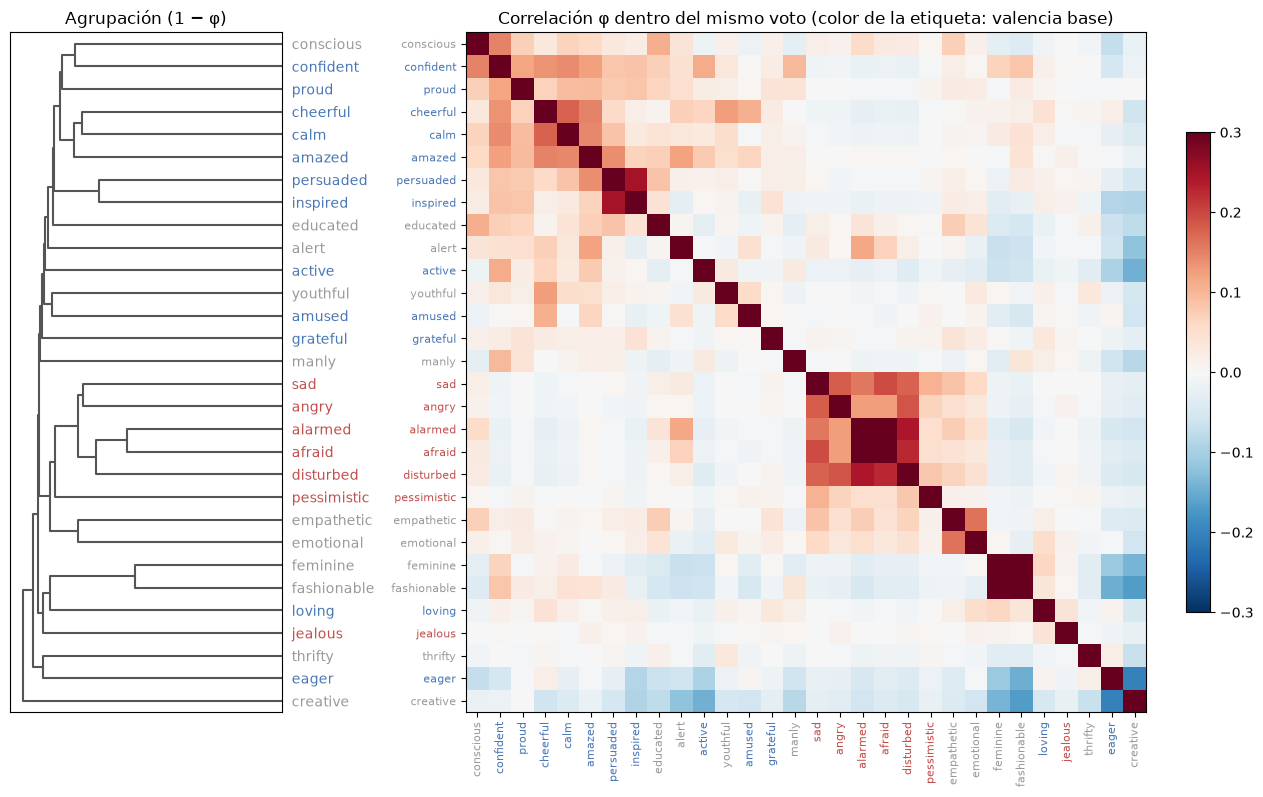

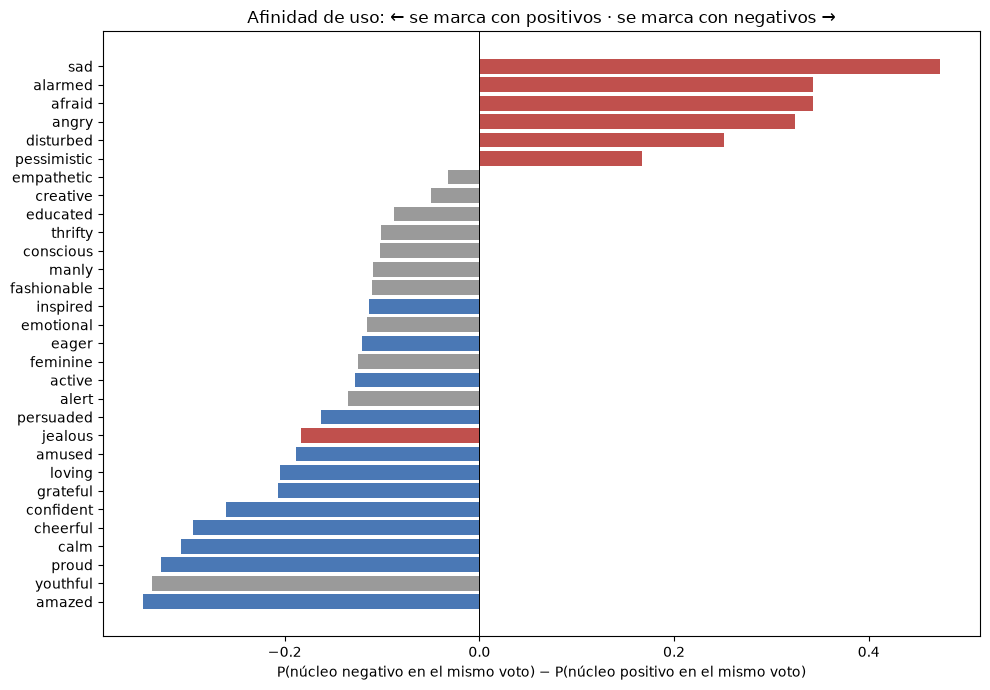

,sentimiento,valencia_base,votos,con_nucleo_negativo,con_nucleo_positivo,afinidad
0,amazed,Positiva,3041,0.019,0.365,-0.346
1,youthful,Neutra,2177,0.011,0.347,-0.336
2,proud,Positiva,805,0.014,0.340,-0.327
3,calm,Positiva,3295,0.006,0.312,-0.306
4,cheerful,Positiva,5700,0.004,0.298,-0.294
5,confident,Positiva,6284,0.007,0.267,-0.260
6,grateful,Positiva,663,0.036,0.243,-0.207
7,loving,Positiva,1336,0.009,0.213,-0.204
8,amused,Positiva,3871,0.017,0.205,-0.188
9,jealous,Negativa,202,0.059,0.243,-0.183


In [3]:
V = np.array([[s in v for s in SENTS] for k in KEYS for v in VOTOS[k]], dtype=float)   # votos × sentimientos
phi = np.corrcoef(V.T)
np.fill_diagonal(phi, 1)
Lk = linkage(squareform(1 - phi, checks=False), method='average')

fig = plt.figure(figsize=(16, 8))
ax_d = fig.add_axes([0.05, 0.08, 0.17, 0.85])
dn = dendrogram(Lk, orientation='left', labels=SENTS, ax=ax_d, color_threshold=0, above_threshold_color='#555')
orden = dn['ivl'][::-1]
for t in ax_d.get_yticklabels():
    t.set_color(COL[val_base(t.get_text())])
ax_d.set_xticks([]); ax_d.set_title('Agrupación (1 − φ)')
ax_h = fig.add_axes([0.3, 0.08, 0.5, 0.85])
o = [si[s] for s in orden]
im = ax_h.imshow(phi[np.ix_(o, o)], cmap='RdBu_r', vmin=-0.3, vmax=0.3)
ax_h.set_xticks(range(len(o)), orden, rotation=90, fontsize=8); ax_h.set_yticks(range(len(o)), orden, fontsize=8)
for t in ax_h.get_xticklabels() + ax_h.get_yticklabels():
    t.set_color(COL[val_base(t.get_text())])
ax_h.set_title('Correlación φ dentro del mismo voto (color de la etiqueta: valencia base)')
fig.colorbar(im, ax=ax_h, fraction=0.03)
plt.savefig(os.path.join(OUT, 'coocurrencia.png'), dpi=150, bbox_inches='tight'); plt.show()

NUC_NEG, NUC_POS = ['afraid', 'angry', 'disturbed', 'sad'], ['cheerful', 'amused', 'calm', 'loving']
af = []
for s in SENTS:
    m = V[:, si[s]] == 1
    otros_neg = [si[x] for x in NUC_NEG if x != s]
    otros_pos = [si[x] for x in NUC_POS if x != s]
    af.append({'sentimiento': s, 'valencia_base': val_base(s), 'votos': int(m.sum()),
               'con_nucleo_negativo': V[m][:, otros_neg].max(1).mean(),
               'con_nucleo_positivo': V[m][:, otros_pos].max(1).mean()})
af = pd.DataFrame(af)
af['afinidad'] = af['con_nucleo_negativo'] - af['con_nucleo_positivo']   # > 0: se usa más junto a negativos
af = af.sort_values('afinidad').reset_index(drop=True)
af.to_csv(os.path.join(OUT, 'afinidad_nucleo.csv'), index=False)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(range(len(af)), af['afinidad'], color=af['valencia_base'].map(COL))
ax.set_yticks(range(len(af)), af['sentimiento']); ax.axvline(0, color='black', lw=0.7)
ax.set(xlabel='P(núcleo negativo en el mismo voto) − P(núcleo positivo en el mismo voto)',
       title='Afinidad de uso: ← se marca con positivos · se marca con negativos →')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'afinidad_nucleo.png'), dpi=150); plt.show()
af

### 1.3 Sentimientos por tema del anuncio

Proporción de votos con cada sentimiento, para los 15 temas más frecuentes (tema = el elegido por la mayoría de anotadores). Permite ver qué temas concentran los sentimientos negativos.

/var/folders/ks/016l_h7n36b1z6g556g971040000gn/T/ipykernel_54657/4217499382.py:17: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  M = M.loc[M[neg_cols].sum(1).sort_values(ascending=False).index]


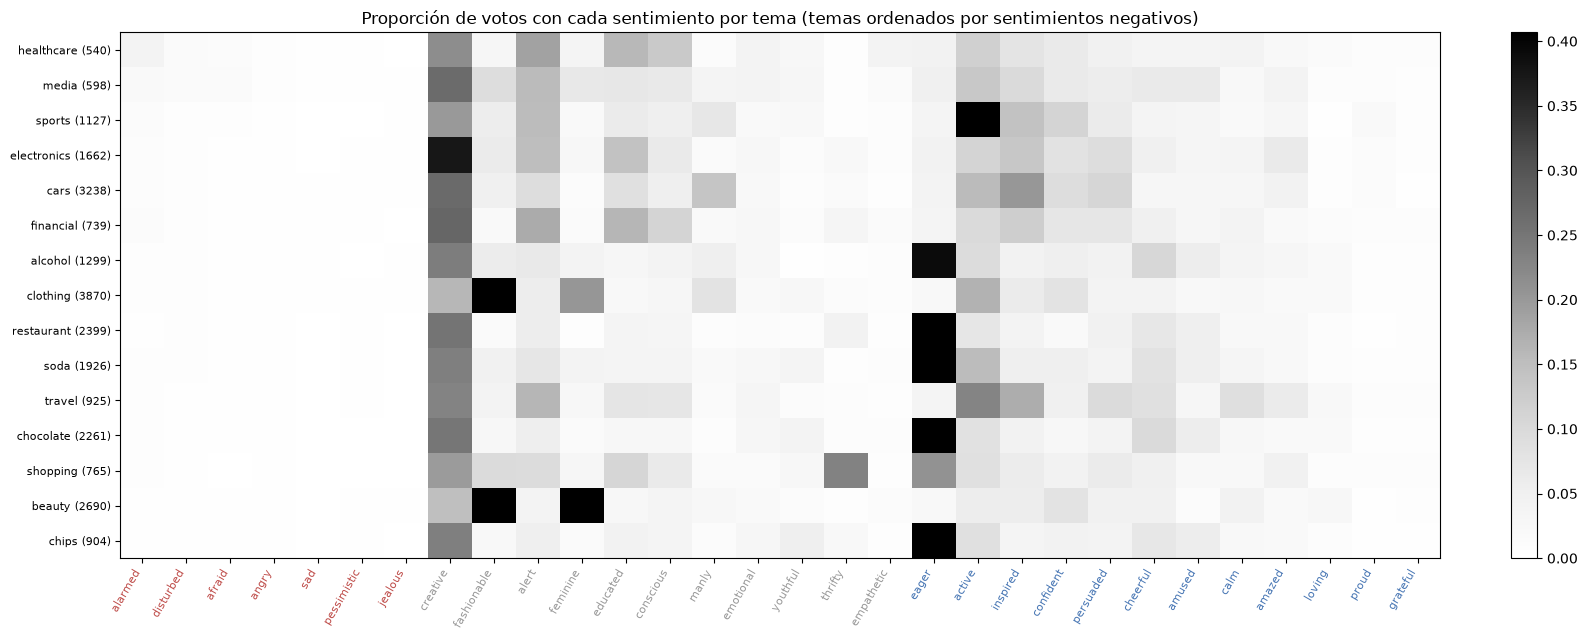

In [4]:
def tema(key):
    v = [str(t).strip() for t in TOPICS.get(key, [])]
    v = [TOPIC_NAMES.get(t, 'other') if t.isdigit() else 'other' for t in v]
    return Counter(v).most_common(1)[0][0] if v else 'other'


temas = pd.Series([tema(k) for k in KEYS], index=KEYS)
top = temas.value_counts().head(15).index
filas = {}
for t in top:
    idx_t = np.where(temas.to_numpy() == t)[0]
    filas[t] = C[idx_t].sum(0) / n_anot[idx_t].sum()
M = pd.DataFrame(filas, index=SENTS).T
cols_ord = list(desc.sort_values(['valencia_base', 'pct_votos'], ascending=[True, False])['sentimiento'])
M = M[cols_ord]
neg_cols = [s for s in cols_ord if s in NEG_BASE]
M = M.loc[M[neg_cols].sum(1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(16, 6.5))
im = ax.imshow(M.to_numpy(), cmap='Greys', aspect='auto', vmax=M.to_numpy().max() * 0.8)
ax.set_xticks(range(M.shape[1]), M.columns, rotation=60, ha='right', fontsize=8)
for t in ax.get_xticklabels():
    t.set_color(COL[val_base(t.get_text())])
ax.set_yticks(range(M.shape[0]), [f'{t} ({(temas == t).sum()})' for t in M.index], fontsize=8)
ax.set_title('Proporción de votos con cada sentimiento por tema (temas ordenados por sentimientos negativos)')
fig.colorbar(im, ax=ax, fraction=0.02)
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'sentimientos_por_tema.png'), dpi=150); plt.show()

## Parte 2 · ¿Cuánto depende el resultado de cómo se construye la valencia?

**Asignaciones** (qué sentimientos cuentan como positivos o negativos; el resto es neutro):

| Variante | Positivos | Negativos | Idea |
|---|---|---|---|
| **base** | active, amazed, amused, calm, cheerful, confident, eager, grateful, inspired, loving, persuaded, proud | afraid, alarmed, angry, disturbed, jealous, pessimistic, sad | La de los notebooks 09–11 |
| **núcleo afectivo** | amused, calm, cheerful, grateful, loving, amazed | afraid, angry, disturbed, sad, alarmed | Solo emociones inequívocas |
| **amplia** | base − persuaded | base + emotional, empathetic | Los sentimientos "conmovedores" de las campañas sociales cuentan como negativos |
| **sin deseo/persuasión** | base − eager, persuaded, confident | base | Quita lo que describe deseo de compra más que emoción |

**Reglas de agregación** (el voto de cada anotador es la valencia con más marcas):
- **mayoría:** la valencia de más de la mitad de los anotadores (la de los notebooks 09–11).
- **≥ 1/3 negativo:** negativo si al menos un tercio de los anotadores vio el anuncio negativo (y no más positivos que negativos); positivo si la mayoría lo vio positivo. Recupera los negativos "en disputa".

*(La unanimidad deja solo 11–40 negativos según la variante: se informa el conteo pero no se evalúa.)*

Para cada combinación: todos los negativos + 2.000 positivos (los primeros de una misma permutación aleatoria, para que las variantes compartan anuncios), **CLIP congelado + sonda, solo imagen**, validación cruzada 5 × 3.

In [5]:
MAPEOS = {
    'base': (POS_BASE, NEG_BASE),
    'núcleo afectivo': ({'amused', 'calm', 'cheerful', 'grateful', 'loving', 'amazed'},
                        {'afraid', 'angry', 'disturbed', 'sad', 'alarmed'}),
    'amplia': (POS_BASE - {'persuaded'}, NEG_BASE | {'emotional', 'empathetic'}),
    'sin deseo/persuasión': (POS_BASE - {'eager', 'persuaded', 'confident'}, NEG_BASE),
}


def votos_valencia(key, pos, neg):
    out = []
    for v in VOTOS[key]:
        p, n = len(v & pos), len(v & neg)
        out.append(0 if p > n else 2 if n > p else 1)   # 0 Pos · 1 Neutro · 2 Neg
    return out


def etiqueta(u, regla):
    c = Counter(u); n = len(u)
    if regla == 'mayoría':
        t, k = c.most_common(1)[0]
        return {0: 'P', 2: 'N'}.get(t) if k / n > 0.5 else None
    if regla == 'unanimidad':
        return {0: 'P', 2: 'N'}.get(u[0]) if len(c) == 1 else None
    if c[2] / n >= 1 / 3 and c[2] >= c[0]:
        return 'N'
    return 'P' if c[0] / n > 0.5 else None


def fleiss(units, K=3):
    P, tot = [], np.zeros(K)
    for u in units:
        c = np.bincount(u, minlength=K); n = len(u); tot += c
        P.append((c * (c - 1)).sum() / (n * (n - 1)))
    p = tot / tot.sum()
    return (np.mean(P) - (p ** 2).sum()) / (1 - (p ** 2).sum())


perm = KEYS.copy()
random.Random(SEED).shuffle(perm)
LAB, conteos = {}, []
for nm, (pos, neg) in MAPEOS.items():
    units = {k: votos_valencia(k, pos, neg) for k in KEYS}
    kap = fleiss(list(units.values()))
    for regla in ('mayoría', '≥ 1/3 negativo', 'unanimidad'):
        lab = {k: etiqueta(u, regla) for k, u in units.items()}
        c = Counter(lab.values())
        conteos.append({'asignación': nm, 'regla': regla, 'positivos': c['P'], 'negativos': c['N'],
                        'κ anotadores (3 clases)': kap})
        if regla != 'unanimidad':
            LAB[(nm, regla)] = lab
conteos = pd.DataFrame(conteos)
display(conteos.set_index(['asignación', 'regla']))

# Muestra de cada variante y universo de imágenes
MUESTRA = {}
for v, lab in LAB.items():
    neg_k = [k for k in perm if lab[k] == 'N']
    pos_k = [k for k in perm if lab[k] == 'P'][:N_POS]
    MUESTRA[v] = sorted(neg_k + pos_k)
ALEATORIA = sorted(perm[:N_RANDOM])
UNIVERSO = sorted(set(ALEATORIA).union(*MUESTRA.values()))

# Coincidencia con la variante base (en los anuncios etiquetados por ambas)
base = LAB[('base', 'mayoría')]
for v, lab in LAB.items():
    comunes = [k for k in KEYS if lab[k] and base[k]]
    conteos.loc[(conteos['asignación'] == v[0]) & (conteos['regla'] == v[1]), 'κ Cohen vs base'] = \
        cohen_kappa_score([base[k] for k in comunes], [lab[k] for k in comunes])
print(f'Universo de imágenes: {len(UNIVERSO)} anuncios')

positivos  negativos  \
asignación           regla                                  
base                 mayoría             15729        265   
                     ≥ 1/3 negativo      15729       1600   
                     unanimidad           3833         13   
núcleo afectivo      mayoría              1678        282   
                     ≥ 1/3 negativo       1678       2002   
                     unanimidad             76         11   
amplia               mayoría             14372        466   
                     ≥ 1/3 negativo      14372       2704   
                     unanimidad           3237         40   
sin deseo/persuasión mayoría              7424        281   
                     ≥ 1/3 negativo       7424       1886   
                     unanimidad           1287         13   

                                     κ anotadores (3 clases)  
asignación           regla                                    
base                 mayoría                           0.078  
                     ≥ 1/3 negativo                    0.078  
                     unanimidad                        0.078  
núcleo afectivo      mayoría                           0.001  
                     ≥ 1/3 negativo                    0.001  
                     unanimidad                        0.001  
amplia               mayoría                           0.079  
                     ≥ 1/3 negativo                    0.079  
                     unanimidad                        0.079  
sin deseo/persuasión mayoría                           0.063  
                     ≥ 1/3 negativo                    0.063  
                     unanimidad                        0.063

Universo de imágenes: 8558 anuncios


### Imágenes y embeddings de CLIP (mismo preprocesamiento que el notebook 10)

In [6]:
local_name = lambda key: key.replace('/', '_').rsplit('.', 1)[0] + '.jpg'
if PITT_CACHE_ZIP and os.path.exists(PITT_CACHE_ZIP):
    with zipfile.ZipFile(PITT_CACHE_ZIP) as z:
        z.extractall(IMG_DIR)


def bajar(key):
    dst = os.path.join(IMG_DIR, local_name(key))
    if os.path.exists(dst):
        return 'existe'
    try:
        im = Image.open(io.BytesIO(fetch(URL_IMG + key))).convert('RGB')
        s = 256 / min(im.size)
        if s < 1:
            im = im.resize((round(im.width * s), round(im.height * s)), Image.BICUBIC)
        im.save(dst + '.part', 'JPEG', quality=92)
        os.replace(dst + '.part', dst)
        return 'nueva'
    except Exception:
        return 'error'


t0 = time.time()
with ThreadPoolExecutor(max_workers=16) as ex:
    estados = Counter(ex.map(bajar, UNIVERSO))
print(dict(estados), f'· {time.time() - t0:.0f}s')
DISP = [k for k in UNIVERSO if os.path.exists(os.path.join(IMG_DIR, local_name(k)))]

from transformers import CLIPVisionModelWithProjection
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
emb_path = os.path.join(OUT, 'clip_img_emb_universo.npz')
cache = {}
if os.path.exists(emb_path):
    d = np.load(emb_path)
    cache = dict(zip(d['key'], d['X']))
faltan = [k for k in DISP if k not in cache]
if faltan:
    vis = CLIPVisionModelWithProjection.from_pretrained(CLIP_NAME).to(DEVICE).eval()
    tf = T.Compose([T.Resize((224, 224)), T.ToTensor(),
                    T.Normalize([0.48145466, 0.4578275, 0.40821073], [0.26862954, 0.26130258, 0.27577711])])
    t0 = time.time()
    with torch.no_grad():
        for i in range(0, len(faltan), 64):
            ks = faltan[i:i + 64]
            x = torch.stack([tf(Image.open(os.path.join(IMG_DIR, local_name(k))).convert('RGB')) for k in ks]).to(DEVICE)
            e = torch.nn.functional.normalize(vis(pixel_values=x).image_embeds.float(), dim=-1).cpu().numpy()
            cache.update(zip(ks, e))
    np.savez(emb_path, key=np.array(list(cache), dtype=str), X=np.stack(list(cache.values())))
    print(f'{len(faltan)} embeddings nuevos en {time.time() - t0:.0f}s')
EMB = cache
print(f'{len(DISP)} anuncios con imagen y embedding')

/private/tmp/claude-501/-Users-miguelcarrascoudp-Documents-GitHub-publicity-analysis/9d4b2e34-c6c2-43a1-bb9e-97865f2c2b02/scratchpad/venv_t2/lib/python3.14/site-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (141750000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/private/tmp/claude-501/-Users-miguelcarrascoudp-Documents-GitHub-publicity-analysis/9d4b2e34-c6c2-43a1-bb9e-97865f2c2b02/scratchpad/venv_t2/lib/python3.14/site-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (112480000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


{'nueva': 6099, 'existe': 1500, 'error': 959} · 13622s


/private/tmp/claude-501/-Users-miguelcarrascoudp-Documents-GitHub-publicity-analysis/9d4b2e34-c6c2-43a1-bb9e-97865f2c2b02/scratchpad/venv_t2/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1123 17:59:50.878000 54657 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 200/200 [00:00<00:00, 55235.45it/s]


7599 embeddings nuevos en 76s
7599 anuncios con imagen y embedding


### Resultado por variante (solo imagen)

Métricas fuera de pliegue, media de 3 repeticiones. Las que no dependen de la proporción de clases (**ROC-AUC**, **balanced accuracy**, **macro-F1**) son las comparables entre variantes, que tienen proporciones de negativos muy distintas.

In [7]:
N_SPLITS, N_REPEATS = 5, 3
C_GRID = {'logisticregression__C': [1e-2, 1e-1, 1.0]}


def sonda_cv(X, y, n_rep=N_REPEATS, scoring='roc_auc'):
    cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=n_rep, random_state=SEED)
    P = np.zeros((len(y), n_rep))
    for k, (tr, te) in enumerate(cv.split(X, y)):
        gs = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=3000)),
                          C_GRID, scoring=scoring, cv=StratifiedKFold(3, shuffle=True, random_state=k)).fit(X[tr], y[tr])
        P[te, k // N_SPLITS] = gs.predict_proba(X[te])[:, 1]
    return P


def metricas(y, P):
    pr = P >= 0.5
    m = lambda f: np.mean([f(y, pr[:, j]) for j in range(P.shape[1])])
    return {'roc_auc': np.mean([roc_auc_score(y, P[:, j]) for j in range(P.shape[1])]),
            'balanced_acc': m(balanced_accuracy_score), 'macro_f1': m(lambda a, b: f1_score(a, b, average='macro')),
            'f1_negativo': m(f1_score), 'accuracy': m(lambda a, b: (a == b).mean())}


g = np.random.default_rng(SEED)
filas = []
for (nm, regla), keys in MUESTRA.items():
    keys = [k for k in keys if k in EMB]
    lab = LAB[(nm, regla)]
    X = np.stack([EMB[k] for k in keys]); y = np.array([lab[k] == 'N' for k in keys], int)
    t0 = time.time()
    P = sonda_cv(X, y)
    r = {'asignación': nm, 'regla': regla, 'anuncios': len(y), 'negativos': int(y.sum()),
         'pct_neg': y.mean(), **metricas(y, P)}
    b = [metricas(y[i], P[i])['balanced_acc'] for i in (g.integers(0, len(y), len(y)) for _ in range(300))]
    r['balanced_acc_ic95'] = f'[{np.percentile(b, 2.5):.3f}, {np.percentile(b, 97.5):.3f}]'
    filas.append(r)
    print(f'{nm} · {regla}: AUC {r["roc_auc"]:.3f} · bal acc {r["balanced_acc"]:.3f} · macro-F1 {r["macro_f1"]:.3f} '
          f'· {time.time() - t0:.0f}s', flush=True)
sens = pd.DataFrame(filas).merge(conteos[['asignación', 'regla', 'κ anotadores (3 clases)', 'κ Cohen vs base']],
                                 on=['asignación', 'regla'])
sens.to_csv(os.path.join(OUT, 'sensibilidad_valencia.csv'), index=False)
display(sens.set_index(['asignación', 'regla']))

base · mayoría: AUC 0.959 · bal acc 0.879 · macro-F1 0.846 · 3s
base · ≥ 1/3 negativo: AUC 0.844 · bal acc 0.770 · macro-F1 0.770 · 4s
núcleo afectivo · mayoría: AUC 0.944 · bal acc 0.863 · macro-F1 0.834 · 3s
núcleo afectivo · ≥ 1/3 negativo: AUC 0.804 · bal acc 0.726 · macro-F1 0.726 · 4s
amplia · mayoría: AUC 0.932 · bal acc 0.861 · macro-F1 0.835 · 905s
amplia · ≥ 1/3 negativo: AUC 0.795 · bal acc 0.721 · macro-F1 0.719 · 5s
sin deseo/persuasión · mayoría: AUC 0.946 · bal acc 0.869 · macro-F1 0.828 · 6s
sin deseo/persuasión · ≥ 1/3 negativo: AUC 0.805 · bal acc 0.727 · macro-F1 0.728 · 7s


anuncios  negativos  pct_neg  roc_auc  \
asignación           regla                                                   
base                 mayoría             2089        265    0.127    0.959   
                     ≥ 1/3 negativo      3182       1358    0.427    0.844   
núcleo afectivo      mayoría             1864        279    0.150    0.944   
                     ≥ 1/3 negativo      3300       1715    0.520    0.804   
amplia               mayoría             2253        425    0.189    0.932   
                     ≥ 1/3 negativo      4102       2274    0.554    0.795   
sin deseo/persuasión mayoría             2125        278    0.131    0.946   
                     ≥ 1/3 negativo      3463       1616    0.467    0.805   

                                     balanced_acc  macro_f1  f1_negativo  \
asignación           regla                                                 
base                 mayoría                0.879     0.846        0.735   
                     ≥ 1/3 negativo         0.770     0.770        0.737   
núcleo afectivo      mayoría                0.863     0.834        0.722   
                     ≥ 1/3 negativo         0.726     0.726        0.729   
amplia               mayoría                0.861     0.835        0.739   
                     ≥ 1/3 negativo         0.721     0.719        0.740   
sin deseo/persuasión mayoría                0.869     0.828        0.708   
                     ≥ 1/3 negativo         0.727     0.728        0.707   

                                     accuracy balanced_acc_ic95  \
asignación           regla                                        
base                 mayoría            0.925    [0.857, 0.900]   
                     ≥ 1/3 negativo     0.774    [0.756, 0.784]   
núcleo afectivo      mayoría            0.908    [0.837, 0.884]   
                     ≥ 1/3 negativo     0.726    [0.713, 0.739]   
amplia               mayoría            0.892    [0.841, 0.880]   
                     ≥ 1/3 negativo     0.721    [0.710, 0.734]   
sin deseo/persuasión mayoría            0.912    [0.846, 0.889]   
                     ≥ 1/3 negativo     0.729    [0.714, 0.740]   

                                     κ anotadores (3 clases)  κ Cohen vs base  
asignación           regla                                                     
base                 mayoría                           0.078            1.000  
                     ≥ 1/3 negativo                    0.078            1.000  
núcleo afectivo      mayoría                           0.001            1.000  
                     ≥ 1/3 negativo                    0.001            0.500  
amplia               mayoría                           0.079            0.990  
                     ≥ 1/3 negativo                    0.079            0.771  
sin deseo/persuasión mayoría                           0.063            1.000  
                     ≥ 1/3 negativo                    0.063            0.708

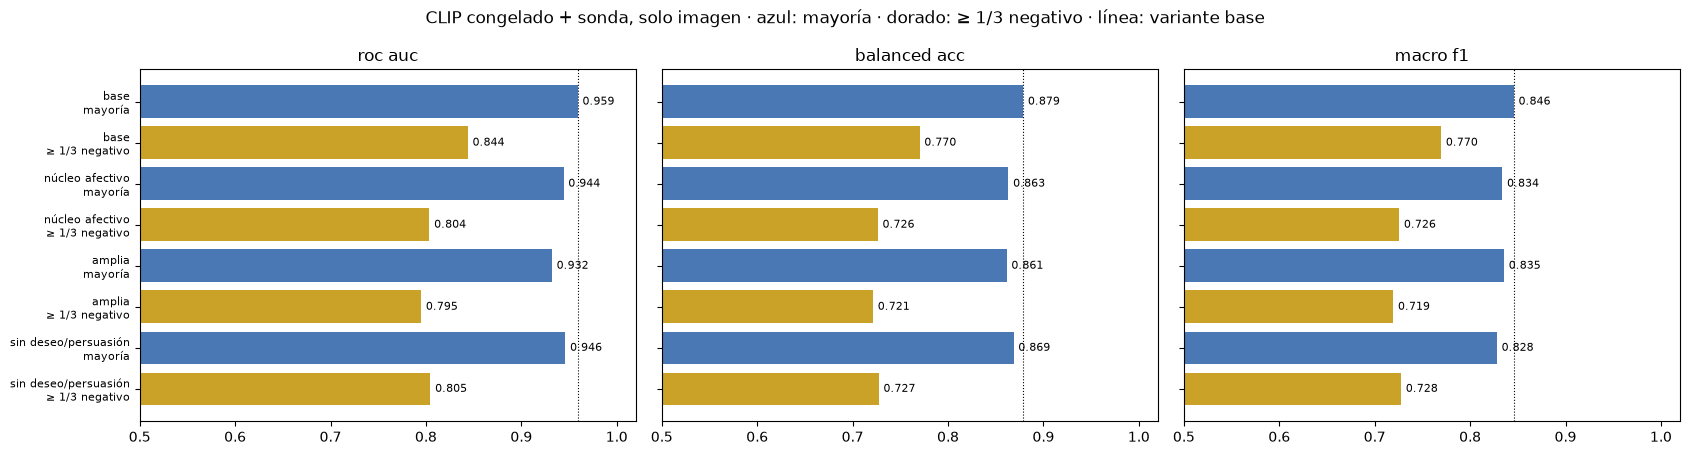

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
etq = [f'{a}\n{r}' for a, r in zip(sens['asignación'], sens['regla'])]
colr = ['#4a78b5' if r == 'mayoría' else '#c9a227' for r in sens['regla']]
for ax, met in zip(axes, ['roc_auc', 'balanced_acc', 'macro_f1']):
    ax.barh(range(len(sens)), sens[met], color=colr)
    for i, v in enumerate(sens[met]):
        ax.text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=8)
    base_v = sens.loc[(sens['asignación'] == 'base') & (sens['regla'] == 'mayoría'), met].iloc[0]
    ax.axvline(base_v, color='black', ls=':', lw=0.8)
    ax.set(xlim=(0.5, 1.02), title=met.replace('_', ' '))
axes[0].set_yticks(range(len(sens)), etq, fontsize=8); axes[0].invert_yaxis()
fig.suptitle('CLIP congelado + sonda, solo imagen · azul: mayoría · dorado: ≥ 1/3 negativo · línea: variante base')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'sensibilidad_valencia.png'), dpi=150); plt.show()

## Parte 3 · ¿Qué sentimientos reconoce CLIP desde la imagen?

En una **muestra aleatoria** de 3.000 anuncios (sin seleccionar por valencia), para cada sentimiento: el anuncio "lo tiene" si **más de la mitad** de sus anotadores lo marcó. Una sonda por sentimiento (solo imagen) y su **ROC-AUC** fuera de pliegue (0,5 = azar). Se omiten los sentimientos con menos de 20 anuncios.

Se compara con el **acuerdo humano** (κ de la parte 1): si un sentimiento tiene AUC alto pese a bajo acuerdo, la imagen contiene información aunque las personas no coincidan al nombrarlo.

15 sentimientos evaluados en 10s · omitidos (< 20 anuncios): ['afraid', 'alarmed', 'amazed', 'angry', 'calm', 'disturbed', 'emotional', 'empathetic', 'grateful', 'jealous', 'loving', 'pessimistic', 'proud', 'sad', 'thrifty']


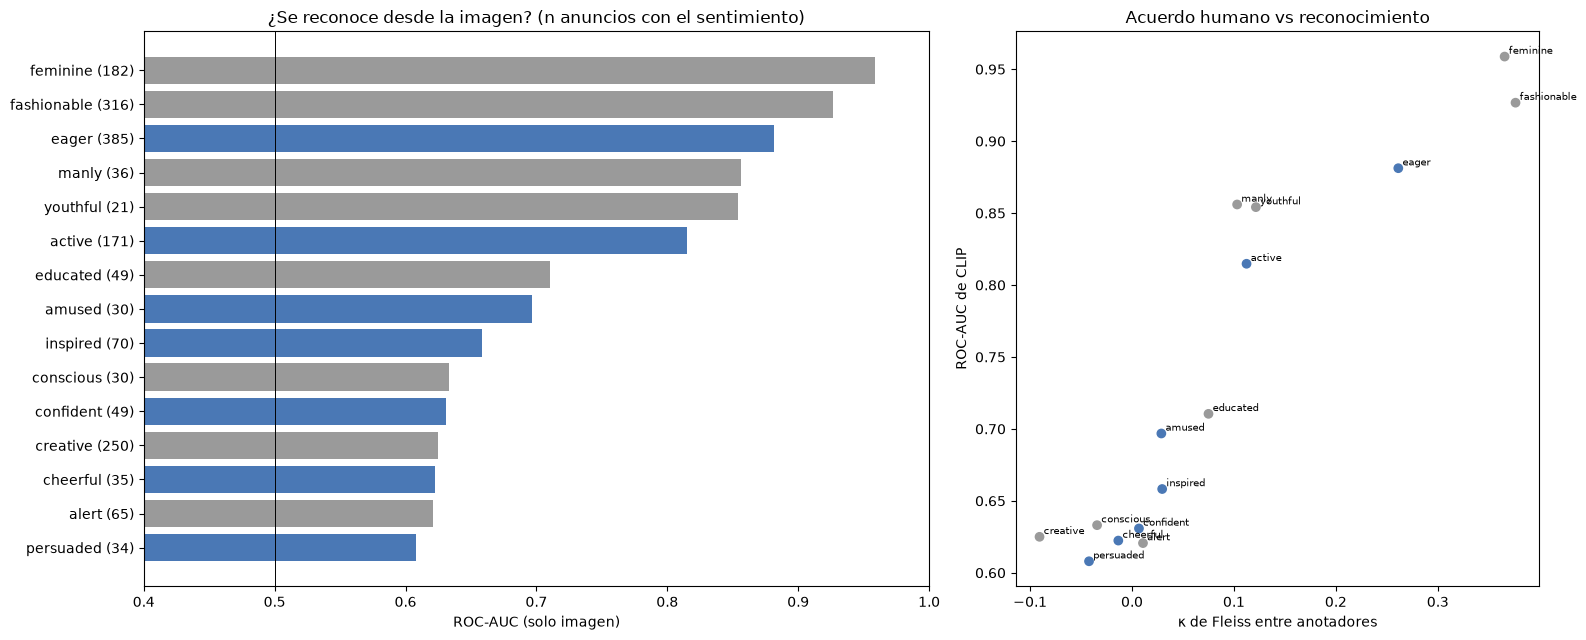

,sentimiento,valencia_base,anuncios_con_sentimiento,roc_auc,kappa
10,feminine,Neutra,182,0.959,0.366
9,fashionable,Neutra,316,0.927,0.376
7,eager,Positiva,385,0.881,0.261
12,manly,Neutra,36,0.856,0.103
14,youthful,Neutra,21,0.854,0.122
0,active,Positiva,171,0.815,0.112
8,educated,Neutra,49,0.710,0.075
2,amused,Positiva,30,0.697,0.029
11,inspired,Positiva,70,0.658,0.030
5,conscious,Neutra,30,0.633,-0.034


In [9]:
keys_r = [k for k in ALEATORIA if k in EMB]
Xr = np.stack([EMB[k] for k in keys_r])
pos_k = {k: i for i, k in enumerate(KEYS)}
Cr = C[[pos_k[k] for k in keys_r]]
nr = n_anot[[pos_k[k] for k in keys_r]]
filas = []
t0 = time.time()
for s in SENTS:
    y = (Cr[:, si[s]] / nr > 0.5).astype(int)
    if y.sum() < 20:
        continue
    P = sonda_cv(Xr, y, n_rep=1)
    filas.append({'sentimiento': s, 'valencia_base': val_base(s), 'anuncios_con_sentimiento': int(y.sum()),
                  'roc_auc': roc_auc_score(y, P[:, 0])})
rec = pd.DataFrame(filas).merge(desc[['sentimiento', 'kappa']], on='sentimiento').sort_values('roc_auc', ascending=False)
rec.to_csv(os.path.join(OUT, 'reconocimiento_por_sentimiento.csv'), index=False)
print(f'{len(rec)} sentimientos evaluados en {time.time() - t0:.0f}s · omitidos (< 20 anuncios):',
      sorted(set(SENTS) - set(rec['sentimiento'])))

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={'width_ratios': [3, 2]})
ax = axes[0]
ax.barh(range(len(rec)), rec['roc_auc'], color=rec['valencia_base'].map(COL))
ax.set_yticks(range(len(rec)), [f"{s} ({n})" for s, n in zip(rec['sentimiento'], rec['anuncios_con_sentimiento'])])
ax.invert_yaxis(); ax.axvline(0.5, color='black', lw=0.7)
ax.set(xlim=(0.4, 1), xlabel='ROC-AUC (solo imagen)', title='¿Se reconoce desde la imagen? (n anuncios con el sentimiento)')
ax = axes[1]
ax.scatter(rec['kappa'], rec['roc_auc'], c=rec['valencia_base'].map(COL))
for _, r in rec.iterrows():
    ax.annotate(r['sentimiento'], (r['kappa'], r['roc_auc']), fontsize=7, xytext=(3, 2), textcoords='offset points')
ax.set(xlabel='κ de Fleiss entre anotadores', ylabel='ROC-AUC de CLIP', title='Acuerdo humano vs reconocimiento')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'reconocimiento_por_sentimiento.png'), dpi=150); plt.show()
rec

## Cómo leer los resultados

- **Parte 1:** si los sentimientos negativos forman un grupo propio en el dendrograma y la afinidad ubica a los ambiguos de un lado claro, la asignación manual tiene respaldo en el uso que hicieron los anotadores. Los κ bajos indican qué sentimientos son poco confiables como etiqueta.
- **Parte 2:** si ROC-AUC, *balanced accuracy* y macro-F1 cambian poco entre variantes, **la conclusión del notebook 10 no depende de la asignación elegida**. Una caída grande con una variante dice qué decisión importa.
- **Parte 3:** los sentimientos con AUC alto son los que la imagen "muestra" (suelen estar ligados al tema del anuncio); los cercanos a 0,5 no se pueden recuperar desde la imagen con este modelo.